# Figure D1 — cost per step against pulse length

What one optimiser step is made of, component by component, as the pulse
lengthens.

In [7]:
from common import *


In [8]:
PIECES = (
    "GEOPE: Jacobian",  # propagator + Jacobian propagator + projection
    "GEOPE: logm",  # one d x d matrix log, plus its coefficients
    "GEOPE: lstsq",  # linear_comb_projected_coeffs_multigate
    "Newton: gradient",  # manifold.value_and_grad
    "Newton: Hessian",  # manifold.hessian, (P, P)
    "Newton: eigh solve",  # newton_saddle_free_step
    "LBFGS: gradient",  # manifold.value_and_grad, again -- see below
)
GEOPE_PIECES = [p for p in PIECES if p.startswith("GEOPE")]
NEWTON_PIECES = [p for p in PIECES if p.startswith("Newton")]
LBFGS_PIECES = [p for p in PIECES if p.startswith("LBFGS")]

L_GRID = {
    **{p: [12, 25, 50, 100, 200, 400, 800, 1200, 1600] for p in GEOPE_PIECES},
    **{p: [12, 25, 50, 100, 200, 400, 800, 1200, 1600] for p in NEWTON_PIECES},
    **{p: [12, 25, 50, 100, 200, 400, 800, 1200, 1600] for p in LBFGS_PIECES},
}

ROUNDS, WARMUP, REPEATS = 15, 5, 1

def cost_components(n, steps, wanted=PIECES):
    """The requested pieces of one iteration, as jitted callables.
    """
    wanted = set(wanted)
    params = make_parameters(n, steps, "CCX")
    Geope(params)  # writes the drift columns before any Jacobian is read
    manifold = params.manifold
    free = params.free()
    target = manifold.target
    pieces = {}

    if wanted & set(GEOPE_PIECES):

        @jax.jit
        def geope_jacobian(phi):
            return manifold.context(phi).omegas

        @jax.jit
        def geope_logm(point):
            return manifold.coefficients(point, -manifold.log(point, target))

        point = manifold.compute_point(free)
        pieces["GEOPE: Jacobian"] = (geope_jacobian, (free,))
        pieces["GEOPE: logm"] = (geope_logm, (point,))
        if "GEOPE: lstsq" in wanted:
            omegas, gammas = geope_jacobian(free), geope_logm(point)
            geope_solve = jax.jit(
                lambda om, ga: linear_comb_projected_coeffs_multigate(om, ga, None)
            )
            pieces["GEOPE: lstsq"] = (geope_solve, (omegas, gammas))

    if "Newton: gradient" in wanted:
        pieces["Newton: gradient"] = (jax.jit(manifold.value_and_grad), (free,))
    if wanted & {"Newton: Hessian", "Newton: eigh solve"}:
        newton_hessian = jax.jit(manifold.hessian)
        pieces["Newton: Hessian"] = (newton_hessian, (free,))
        if "Newton: eigh solve" in wanted:
            hessian = newton_hessian(free)
            _value, grad = manifold.value_and_grad(free)
            pieces["Newton: eigh solve"] = (
                jax.jit(newton_saddle_free_step),
                (hessian, jnp.real(grad).flatten()),
            )

    if "LBFGS: gradient" in wanted:
        pieces["LBFGS: gradient"] = (jax.jit(manifold.value_and_grad), (free,))

    unbuilt = wanted - set(pieces)
    assert not unbuilt, f"PIECES is out of step with what is timed: {sorted(unbuilt)}"
    return {p: pieces[p] for p in PIECES if p in pieces}, int(free.size)


In [9]:
def cost_paths(cfg):
    """``(npz, json)`` for one ``(piece, L)`` block"""
    return cache_paths(cfg, "cost", piece_slug(cfg["piece"]))

def cost_config(n, steps, piece):
    """Everything that changes this block's numbers.
    """
    return {
        "tag": f"cost_n{n}_L{steps}_{piece_slug(piece)}",
        "kind": "cost-per-step",
        "n_qubits": n,
        "L": steps,
        "piece": piece,
        "rounds": ROUNDS,
        "warmup": WARMUP,
    }

def cost_sweep(n=None, repeats=None, force=False, verbose=True):
    """Every ``(piece, L)`` block, as a tidy DataFrame of seconds.

    Iterates L-major so each pulse length builds its callables **once**, and
    only the ones that are both wanted at that L and not already cached — a
    fully cached sweep therefore never touches JAX at all.
    """
    n = 3 if n is None else n
    repeats = REPEATS if repeats is None else repeats
    rows = []

    for steps in sorted({length for grid in L_GRID.values() for length in grid}):
        wanted = [p for p in PIECES if steps in L_GRID[p]]
        stored = {}
        for piece in wanted:
            npz_path, _ = cost_paths(cost_config(n, steps, piece))
            if npz_path.exists() and not force:
                with np.load(npz_path) as handle:
                    stored[piece] = ([*handle["samples"]], int(handle["P"]))
            else:
                stored[piece] = ([], None)

        todo = [p for p in wanted if len(stored[p][0]) < repeats]
        if todo and verbose:
            # Building is not free either: it compiles each callable and
            # evaluates the Hessian a downstream piece needs as its argument.
            print(f"  L={steps}: building {', '.join(todo)}", flush=True)
        built, built_params = cost_components(n, steps, todo) if todo else ({}, None)

        for piece in wanted:
            cfg = cost_config(n, steps, piece)
            npz_path, json_path = cost_paths(cfg)
            samples, n_params = stored[piece]
            have = len(samples)

            if piece not in todo:
                note = f"cached ({have} batches)"
            else:
                fn, args = built[piece]
                n_params = built_params
                started = time.perf_counter()
                beat = f"L{steps} {piece}" if verbose else ""
                # The warm-up is `time_batch` with its result thrown away: the
                # same calls, and the same heartbeat while it makes them.
                time_batch(fn, args, rounds=WARMUP, label=f"{beat} warm-up" if beat else "")
                for batch in range(have, repeats):
                    samples.append(time_batch(fn, args, rounds=ROUNDS, label=beat))
                    if verbose:
                        print(
                            f"      {beat} batch {batch + 1}/{repeats}  "
                            f"median {float(np.median(samples[-1])) * 1e3:.1f} ms",
                            flush=True,
                        )
                    # Written after every batch: one eigh batch at L=400 runs
                    # for over a minute, so an interrupt should cost a batch.
                    npz_path.parent.mkdir(parents=True, exist_ok=True)
                    np.savez_compressed(
                        npz_path,
                        samples=np.asarray(samples),
                        L=np.asarray(steps),
                        P=np.asarray(n_params),
                    )
                    json_path.write_text(
                        json.dumps(
                            {**cfg, "repeats": len(samples), "P": n_params},
                            indent=1,
                            sort_keys=True,
                        )
                    )
                note = (
                    f"computed {repeats - have} of {repeats} in "
                    f"{time.perf_counter() - started:.0f}s"
                )

            rows.append(
                {
                    "piece": piece,
                    "L": steps,
                    "P": n_params,
                    "seconds": reduce_samples(samples[:repeats]),
                }
            )
            if verbose:
                print(
                    f"  {cfg['tag']:38s} {rows[-1]['seconds'] * 1e3:10.3f} ms   {note}",
                    flush=True,
                )

    return pd.DataFrame(rows)

cost_df = cost_sweep()


  cost_n3_L12_GEOPE-Jacobian                  0.783 ms   cached (4 batches)
  cost_n3_L12_GEOPE-logm                      0.057 ms   cached (4 batches)
  cost_n3_L12_GEOPE-lstsq                     0.466 ms   cached (4 batches)
  cost_n3_L12_Newton-gradient                 0.381 ms   cached (4 batches)
  cost_n3_L12_Newton-Hessian                  1.801 ms   cached (4 batches)
  cost_n3_L12_Newton-eigh-solve               0.803 ms   cached (4 batches)
  cost_n3_L12_LBFGS-gradient                  0.313 ms   cached (4 batches)
  cost_n3_L25_GEOPE-Jacobian                  1.542 ms   cached (4 batches)
  cost_n3_L25_GEOPE-logm                      0.046 ms   cached (4 batches)
  cost_n3_L25_GEOPE-lstsq                     0.768 ms   cached (4 batches)
  cost_n3_L25_Newton-gradient                 0.740 ms   cached (4 batches)
  cost_n3_L25_Newton-Hessian                  3.799 ms   cached (4 batches)
  cost_n3_L25_Newton-eigh-solve               3.404 ms   cached (4 batches)
  cost_n3_L2

In [10]:
from geope.jax.jacobian import _prefix_suffix

# One row of the Newton Hessian: Goodwin & Vinding against the naive route.

ROW_PIECES = ("Hessian row: naive", "Hessian row: Goodwin-Vinding")
ROW_L = L_GRID["Newton: Hessian"]


def hessian_row_fns(params):
    """Row ``(L // 2, 0)`` of ``params.manifold.hessian``, one jitted fn per route.

    Returns:
        ``({piece: phi -> (P,)}, a)``, with ``a`` the row's flat index.
    """
    manifold = params.manifold
    basis = jnp.asarray(manifold.tangent.generators.basis)  # already -dt * G_k
    target = jnp.asarray(manifold.target)
    n_gates, n_coeffs, d = params.piecewise_steps, basis.shape[0], basis.shape[-1]
    i, k = n_gates // 2, 0
    gate_index = jnp.arange(n_gates)
    below, above = (gate_index < i)[:, None], (gate_index > i)[:, None]
    eye = jnp.eye(d, dtype=jnp.complex128)

    def shared(phi):
        gates = jax.vmap(partial(Ui, basis=basis))(phi)  # (G, d, d)
        dU = jax.vmap(partial(dexpm_eig, basis=basis))(phi)  # (G, d, d, K)
        Ls, Rs = _prefix_suffix(gates)
        point = gates[-1] @ Rs[-1]
        J = jnp.einsum("iab,ibek,iec->iack", Ls, dU, Rs)  # Jacobian trajectory
        cov_h = jnp.conj(manifold.cost_gradient(point, target)).T  # G^dag
        # Same-gate block: the second derivative of gate i alone.
        d2 = d2expm_eig(phi[i], basis)[:, :, k, :]  # (d, d, K)
        diag = jnp.einsum("ab,bc,cel,ea->l", cov_h, Ls[i], d2, Rs[i])
        # The SU cost's own curvature (`trace_cost_hessian_form`, kappa = d): O(P).
        zeta = jnp.einsum("ab,gabl->gl", jnp.conj(target), J)
        z = jnp.sum(jnp.conj(target) * point)
        r, re = jnp.abs(z), jnp.real(jnp.conj(z) * zeta)
        first = jnp.real(jnp.conj(zeta[i, k]) * zeta) / r
        cost = -(first - re[i, k] * re / r**3) / d
        return gates, dU, Ls, Rs, point, J, cov_h, diag, cost

    def assemble(lower, upper, diag, cost):
        chart = jnp.where(below, lower, jnp.where(above, upper, diag[None, :]))
        return (cost + 2.0 * jnp.real(chart)).ravel()

    @jax.jit
    def goodwin_vinding(phi):
        _gates, _dU, _Ls, _Rs, point, J, cov_h, diag, cost = shared(phi)
        u_h, J_ik = jnp.conj(point).T, J[i, :, :, k]
        lower = jnp.einsum("ab,gbal->gl", cov_h @ J_ik @ u_h, J)
        upper = jnp.einsum("ab,gbal->gl", u_h @ J_ik @ cov_h, J)
        return assemble(lower, upper, diag, cost)

    @jax.jit
    def naive(phi):
        gates, dU, Ls, Rs, _point, _J, cov_h, diag, cost = shared(phi)

        def central(j):
            # U_{hi-1} ... U_{lo+1}, rebuilt from scratch for this element.
            lo, hi = jnp.minimum(i, j), jnp.maximum(i, j)

            def step(M, gate):
                g, U = gate
                return jnp.where((lo < g) & (g < hi), U, eye) @ M, None

            return jax.lax.scan(step, eye, (gate_index, gates))[0]

        M = jax.vmap(central)(gate_index)  # (G, d, d)
        X = jnp.einsum("jab,bc,jcd->jad", Rs, cov_h @ Ls[i] @ dU[i, :, :, k], M)
        Y = jnp.einsum("jab,bc,jcd->jad", M, dU[i, :, :, k] @ Rs[i] @ cov_h, Ls)
        lower = jnp.einsum("jab,jbal->jl", X, dU)
        upper = jnp.einsum("jab,jbal->jl", Y, dU)
        return assemble(lower, upper, diag, cost)

    fns = {"Hessian row: naive": naive, "Hessian row: Goodwin-Vinding": goodwin_vinding}
    return fns, i * n_coeffs + k


# --- both rows must be the library's row before either is timed ---------------
_STEPS=25
_params = make_parameters(3, _STEPS, "CCX")
Geope(_params)  # writes the drift columns before any derivative is read
_free = _params.free()
_fns, _row = hessian_row_fns(_params)
_ref = np.asarray(_params.manifold.hessian(_free))[_row]
_dev = {
    p: float(np.max(np.abs(np.asarray(f(_free)) - _ref))) for p, f in _fns.items()
}
print(
    f"L={_STEPS:3d} row {_row}, |max| {np.abs(_ref).max():.3f}: "
    + "  ".join(f"{p} {v:.1e}" for p, v in _dev.items())
)
assert max(_dev.values()) < 1e-11 * max(1.0, np.abs(_ref).max()), _dev


def row_sweep(repeats=None, force=False, verbose=True):
    """Every ``(piece, L)`` row block, as a tidy DataFrame of seconds."""
    repeats = REPEATS if repeats is None else repeats
    rows = []
    for steps in ROW_L:
        fns = None
        for piece in ROW_PIECES:
            cfg = cost_config(3, steps, piece)
            npz_path, json_path = cost_paths(cfg)
            samples, n_params = [], None
            if npz_path.exists() and not force:
                with np.load(npz_path) as handle:
                    samples, n_params = [*handle["samples"]], int(handle["P"])

            have = len(samples)
            if have >= repeats:
                note = f"cached ({have} batches)"
            else:
                if fns is None:  # a fully cached L never builds its callables
                    params = make_parameters(3, steps, "CCX")
                    Geope(params)
                    free = params.free()
                    fns, _row = hessian_row_fns(params)
                n_params = int(free.size)
                started = time.perf_counter()
                beat = f"L{steps} {piece}" if verbose else ""
                fn = fns[piece]
                time_batch(
                    fn, (free,), rounds=WARMUP, label=f"{beat} warm-up" if beat else ""
                )
                for _batch in range(have, repeats):
                    samples.append(time_batch(fn, (free,), rounds=ROUNDS, label=beat))
                    npz_path.parent.mkdir(parents=True, exist_ok=True)
                    np.savez_compressed(
                        npz_path,
                        samples=np.asarray(samples),
                        L=np.asarray(steps),
                        P=np.asarray(n_params),
                    )
                    json_path.write_text(
                        json.dumps(
                            {**cfg, "repeats": len(samples), "P": n_params},
                            indent=1,
                            sort_keys=True,
                        )
                    )
                note = (
                    f"computed {repeats - have} of {repeats} in "
                    f"{time.perf_counter() - started:.0f}s"
                )

            rows.append(
                {
                    "piece": piece,
                    "L": steps,
                    "P": n_params,
                    "seconds": reduce_samples(samples[:repeats]),
                }
            )
            if verbose:
                print(
                    f"  {cfg['tag']:44s} {rows[-1]['seconds'] * 1e3:10.3f} ms   {note}",
                    flush=True,
                )
    return pd.DataFrame(rows)


row_df = row_sweep()
row_wide = row_df.pivot(index="L", columns="piece", values="seconds")[list(ROW_PIECES)]


L= 25 row 108, |max| 0.215: Hessian row: naive 2.9e-16  Hessian row: Goodwin-Vinding 1.1e-16
  cost_n3_L12_Hessian-row-naive                     0.674 ms   cached (1 batches)
  cost_n3_L12_Hessian-row-Goodwin-Vinding           0.611 ms   cached (1 batches)
  cost_n3_L25_Hessian-row-naive                     1.344 ms   cached (1 batches)
  cost_n3_L25_Hessian-row-Goodwin-Vinding           1.166 ms   cached (1 batches)
  cost_n3_L50_Hessian-row-naive                     2.992 ms   cached (1 batches)
  cost_n3_L50_Hessian-row-Goodwin-Vinding           1.814 ms   cached (1 batches)
  cost_n3_L100_Hessian-row-naive                    7.295 ms   cached (1 batches)
  cost_n3_L100_Hessian-row-Goodwin-Vinding          3.056 ms   cached (1 batches)
  cost_n3_L200_Hessian-row-naive                   22.215 ms   cached (1 batches)
  cost_n3_L200_Hessian-row-Goodwin-Vinding          6.130 ms   cached (1 batches)
  cost_n3_L400_Hessian-row-naive                   70.314 ms   cached (1 batches)
  cos

Jacobian ($\propto L^{0.81}$)
Least-squares ($\propto L^{0.93}$)
Matrix log ($\propto L^{0.03}$)
GEOPE ($\propto L^{0.85}$)
L-BFGS ($\propto L^{0.75}$)
Goodwin-Vinding ($\propto L^{1.06}$)
Naive ($\propto L^{1.94}$)
Eigh ($\propto L^{3.34}$)
Hessian ($\propto L^{1.66}$)
Gradient ($\propto L^{0.71}$)
Newton ($\propto L^{3.31}$)
figures/figD1_cost_per_step_n3.pdf


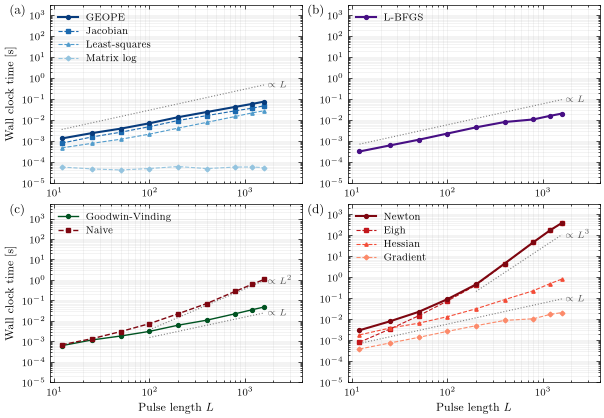

In [18]:
wide = cost_df.pivot(index="L", columns="piece", values="seconds")[list(PIECES)]

blues, reds, greens, purples = plt.cm.Blues, plt.cm.Reds, plt.cm.Greens, plt.cm.Purples
PIECE_STYLES = ((0.78, "s"), (0.58, "^"), (0.40, "D"))
TOTAL_SHADE = 0.95

#: One breakdown panel per algorithm: ``{title: (colour family, pieces, display names)}``.
PANELS = {
    "GEOPE": (
        blues,
        GEOPE_PIECES,
        {
            "GEOPE: Jacobian": "Jacobian",
            "GEOPE: logm": "Matrix log",
            "GEOPE: lstsq": "Least-squares",
        },
    ),
    "Newton": (
        reds,
        NEWTON_PIECES,
        {
            "Newton: gradient": "Gradient",
            "Newton: Hessian": "Hessian",
            "Newton: eigh solve": "Eigh",
        },
    ),
    "L-BFGS": (purples, LBFGS_PIECES, {"LBFGS: gradient": "Fidelity gradient"}),
}
ROW_DRAWN = (
    ("Hessian row: Goodwin-Vinding", greens(0.95), "-", "o", "Goodwin-Vinding"),
    ("Hessian row: naive", reds(0.95), "--", "s", "Naive"),
)
#: Wait until we're asymptotic for fit
FIT_FROM = 100
YLIM = (1e-5, 3e3)
_START=7e-4

def draw_breakdown(ax, name):
    """One algorithm's pieces (dashed) and their total (solid)."""
    family, pieces, names = PANELS[name]
    steps = wide.index.to_numpy(float)
    total = wide[pieces].sum(axis=1).to_numpy(float)
    ordered = sorted(pieces, key=lambda p: -float(wide[p].iloc[-1]))

    for (shade, marker), piece in zip(PIECE_STYLES, ordered if len(pieces) > 1 else ()):
        values = wide[piece].to_numpy(float)
        _coefficients, label = power_fit(names[piece], steps, values, FIT_FROM)
        ax.loglog(
            steps,
            values,
            color=family(shade),
            ls="--",
            lw=0.8,
            marker=marker,
            ms=2.4,
            zorder=3,
            label=label,
        )

    _coefficients, label = power_fit(name, steps, total, FIT_FROM)
    ax.loglog(
        steps,
        total,
        color=family(TOTAL_SHADE),
        ls="-",
        lw=1.5,
        marker="o",
        ms=2.8,
        zorder=4,
        label=label,
    )

    handles, labels = ax.get_legend_handles_labels()
    order = [len(handles) - 1, *range(len(handles) - 1)]
    ax.legend(
        [handles[i] for i in order],
        [labels[i] for i in order],
        loc="upper left",
    ).get_frame().set_linewidth(0.4)
    ax.set_xlim(9, 4000)
    if name == "GEOPE":
        guide = steps[steps >= 10]
        for piece, power, text in ((ROW_PIECES[1], 1, r"$\propto L$"),):
            start = _START
            line = (0.5 * start * (guide / guide[0]) ** power) * 10
            ax.loglog(guide, line, color="0.5", ls=":", lw=0.8, zorder=2)
            ax.text(
                guide[-1] * 1.08,
                line[-1],
                text,
                fontsize=ANNOTATION_SIZE,
                color="0.35",
                va="center",
            )
    elif name == "L-BFGS":
        guide = steps[steps >= 10]
        for piece, power, text in ((ROW_PIECES[1], 1, r"$\propto L$"),):
            start = _START
            line = (0.5 * start * (guide / guide[0]) ** power) * 2
            ax.loglog(guide, line, color="0.5", ls=":", lw=0.8, zorder=2)
            ax.text(
                guide[-1] * 1.08,
                line[-1],
                text,
                fontsize=ANNOTATION_SIZE,
                color="0.35",
                va="center",
            )
    elif name == "Newton":
        guide = steps[steps >= 10]
        for piece, power, text in ((ROW_PIECES[1], 1, r"$\propto L$"),):
            start = _START
            line = (0.5 * start * (guide / guide[0]) ** power) * 2
            ax.loglog(guide, line, color="0.5", ls=":", lw=0.8, zorder=2)
            ax.text(
                guide[-1] * 1.08,
                line[-1],
                text,
                fontsize=ANNOTATION_SIZE,
                color="0.35",
                va="center",
            )
        guide = steps[steps >= FIT_FROM*2]
        for piece, power, text in ((ROW_PIECES[1], 3, r"$\propto L^3$"),):
            start = _START*300
            line = (0.5 * start * (guide / guide[0]) ** power) * 2
            ax.loglog(guide, line, color="0.5", ls=":", lw=0.8, zorder=2)
            ax.text(
                guide[-1] * 1.08,
                line[-1],
                text,
                fontsize=ANNOTATION_SIZE,
                color="0.35",
                va="center",
            )


def draw_hessian_row(ax,row_wide):
    """One Hessian row, Goodwin & Vinding against the naive route."""
    steps = row_wide.index.to_numpy(float)
    for piece, colour, ls, marker, name in ROW_DRAWN:
        values = row_wide[piece].to_numpy(float)
        _coefficients, label = power_fit(name, steps, values, FIT_FROM)
        ax.loglog(
            steps,
            values,
            color=colour,
            ls=ls,
            lw=1.0,
            marker=marker,
            ms=2.8,
            zorder=3,
            label=label,
        )

    # Slope guides, anchored at the first fitted point of each route.
    guide = steps[steps >= FIT_FROM]
    for piece, power, text in (
        (ROW_PIECES[1], 1, r"$\propto L$"),
        (ROW_PIECES[0], 2, r"$\propto L^2$"),
    ):
        start = float(row_wide[piece].loc[int(guide[0])])
        line = 0.5 * start * (guide / guide[0]) ** power
        ax.loglog(guide, line, color="0.5", ls=":", lw=0.8, zorder=2)
        ax.text(
            guide[-1] * 1.08,
            line[-1],
            text,
            fontsize=ANNOTATION_SIZE,
            color="0.35",
            va="center",
        )

    ax.set_xlim(9, 4000)
    ax.legend(loc="upper left").get_frame().set_linewidth(0.4)


fig = plt.figure(figsize=(TWO_COLUMN, 4.9))
gs = fig.add_gridspec(2, 2, wspace=0.18, hspace=0.12)
geope_ax = fig.add_subplot(gs[0, 0])
lbfgs_ax = fig.add_subplot(gs[0, 1], sharey=geope_ax)
row_ax = fig.add_subplot(gs[1, 0])
newton_ax = fig.add_subplot(gs[1, 1], sharey=geope_ax)

draw_breakdown(geope_ax, "GEOPE")
draw_breakdown(lbfgs_ax, "L-BFGS")
draw_hessian_row(row_ax, row_wide)
draw_breakdown(newton_ax, "Newton")


for letter, ax in zip("abcd", (geope_ax, lbfgs_ax, row_ax, newton_ax)):
    ax.grid(alpha=0.25, which="both", lw=0.4)
    panel_label(ax, letter, x=-0.16)
    ax.set_ylim(1e-5, 5000)
for ax in (geope_ax, row_ax):
    ax.set_ylabel("Wall clock time [s]")
for ax in (row_ax, newton_ax):
    ax.set_xlabel(r"Pulse length $L$")
geope_ax.set_ylim(*YLIM)

print(save_figure(fig, f"figD1_cost_per_step_n{3}"))
plt.show()